# [LABO 1] Período de un péndulo y validez de la aproximación de ángulos pequeños

Notebook limpio para Google Colab (y ejecución local) que analiza las trayectorias a **60 fps** (`results/trajectories.csv`):
1. **Configuración, carga de datos, clase `GravedadCalculada` original y calibración geométrica del pivote** $(x_c, y_c, R_{\text{px}})$ para reconstruir $\theta(t) = \operatorname{atan2}(x - x_c, y - y_c)$.
2. **Ajuste sinusoidal individual por video** ($\theta(t) = A\cos(\omega(t - t_0) + \phi) + \theta_{\text{offset}}$) separado en secciones para cada toma (`IMG_1555` a `IMG_1568`; `IMG_1569` excluido temporalmente hasta su verificación manual).
3. **Comparación general** de $T(\theta_0)$ frente al período de referencia de pequeñas oscilaciones $T_0$ y criterio de compatibilidad.
4. **Generación de figuras para Overleaf** siguiendo la convención sin títulos internos en Matplotlib (los títulos van en `\subcaption` y `\caption` de LaTeX).

## 0. Configuración, carga de datos y funciones de ajuste

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, least_squares
from IPython.display import display

# --- Constantes físicas del péndulo ---
LARGO_PENDULO_SIN_BASE = 73.7 / 100.0  # [m]
LARGO_PENDULO_BASE = 77.8 / 100.0      # [m]
LARGO_CM = 0.5 * (LARGO_PENDULO_SIN_BASE + LARGO_PENDULO_BASE)  # 0.7575 m (75,8 cm)
SIGMA_L = 0.5 / 100.0                  # [m]
SIGMA_C = 0.2 / 1000.0                 # [m] incerteza del calibre
G_REF = 9.797                          # [m/s²] gravedad local de referencia (Buenos Aires)

# --- Parámetros de cámara y detección ---
FPS = 60.0
SIGMA_T = 1.0 / FPS                    # [s] período entre fotogramas (~16,67 ms)
SIGMA_X_PX = 1.5                       # [px] incerteza estadística del centroide en x
SIGMA_Y_PX = 1.5                       # [px] incerteza estadística del centroide en y

# --- Videos excluidos temporalmente ---
# Quitar "IMG_1569" de este conjunto cuando se verifique manualmente en debug_frame_detection.ipynb
EXCLUDED_VIDEOS = {"IMG_1569"}

# --- Carga de trajectories.csv (local o Google Drive en Colab) ---
DRIVE_FILE_ID = "1hpsoMIAV7MEFq7sY5r-pHIDj240V9jl5"  # Actualizar ID al subir el CSV de 60 fps a Drive
LOCAL_CANDIDATES = [
    Path("results/trajectories.csv"),
    Path("../results/trajectories.csv"),
    Path("trajectories.csv"),
]

csv_source = next((p for p in LOCAL_CANDIDATES if p.exists()), None)
if csv_source is not None:
    df_all = pd.read_csv(csv_source)
    print(f"CSV cargado localmente desde: {csv_source} ({len(df_all)} filas)")
else:
    drive_url = f"https://drive.google.com/uc?id={DRIVE_FILE_ID}"
    df_all = pd.read_csv(drive_url)
    print(f"CSV cargado desde Google Drive ID={DRIVE_FILE_ID} ({len(df_all)} filas)")

if len(df_all) < 5000:
    print(
        "ADVERTENCIA: El CSV cargado tiene pocas filas (posible versión de 6 fps). "
        "Subir results/trajectories.csv (60 fps, 16517 filas) a Drive y actualizar DRIVE_FILE_ID."
    )

df_active = df_all[~df_all["video_name"].isin(EXCLUDED_VIDEOS)].copy()
resumen_videos = (
    df_active.groupby("video_name", sort=True)
    .agg(
        fotogramas=("t", "size"),
        validos=("x", lambda s: int(s.notna().sum())),
        t_ini=("t", "min"),
        t_fin=("t", "max"),
        x_min=("x", "min"),
        x_max=("x", "max"),
        y_min=("y", "min"),
        y_max=("y", "max"),
    )
)
print(f"Videos activos analizados: {len(resumen_videos)} (excluidos: {sorted(EXCLUDED_VIDEOS)})")
display(resumen_videos)

CSV cargado localmente desde: ../results/trajectories.csv (16517 filas)
Videos activos analizados: 14 (excluidos: ['IMG_1569'])


,fotogramas,validos,t_ini,t_fin,x_min,x_max,y_min,y_max
video_name,,,,,,,,
IMG_1555,1320,1307,0.0,21.9833,276.0,3681.0,1090.0,2042.0
IMG_1556,1020,1020,2.0,18.9833,559.0,3409.0,1417.0,2043.0
IMG_1557,1118,1118,1.0,19.6167,747.0,3188.0,1605.0,2037.0
IMG_1558,1155,1155,0.0,19.2333,1124.0,2780.0,1843.0,2039.0
IMG_1559,1012,1012,2.0,18.8500,1319.0,2598.0,1909.0,2039.0
IMG_1560,1217,1217,0.0,20.2667,1388.0,2507.0,1942.0,2035.0
IMG_1561,1039,1039,2.0,19.3000,1503.0,2396.0,1971.0,2035.0
IMG_1562,900,900,2.0,16.9833,1586.0,2316.0,1986.0,2034.0
IMG_1563,1270,1270,2.0,23.1500,1555.0,2344.0,1981.0,2031.0


### 0.1. Clase `GravedadCalculada` (conservada del Colab original)

In [2]:
import itertools
from pathlib import Path
import av
import skimage
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2

# ==============================================================================
# 1. CLASE ACTUALIZADA CON ERRORES (X, Y, t), CHI CUADRADO Y AMBOS MODELOS
# ==============================================================================
class GravedadCalculada:
    def __init__(
        self,
        df_polar: pd.DataFrame,
        nombre: str = "Experimento",
        con_amortiguamiento: bool = True,
        largo_base: float = LARGO_PENDULO_BASE,
        largo_sin_base: float = LARGO_PENDULO_SIN_BASE,
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ):
        self.nombre = nombre
        self.con_amortiguamiento = con_amortiguamiento
        self.tipo_modelo = "Con Amort." if con_amortiguamiento else "Sin Amort."
        self.largo_base = largo_base
        self.largo_sin_base = largo_sin_base
        self.largo_cm = 0.5 * (largo_base + largo_sin_base)
        self.sigma_l = sigma_l
        self.sigma_t = sigma_t

        self.df_polar = df_polar
        self.df_fit = df_polar.dropna(
            subset=["t", "theta_rad", "sigma_theta_stat_rad"]
        ).copy()

        self.t_data = self.df_fit["t"].values
        self.y_data = self.df_fit["theta_rad"].values
        # Error estadístico (x, y) punto a punto para el ajuste
        self.y_err_stat = self.df_fit["sigma_theta_stat_rad"].values
        # Error total (incluyendo sistemático de L y escala k)
        self.y_err_total = self.df_fit["sigma_theta_total_rad"].values

        self._ajustar()

    # --- PROCESAMIENTO DE VIDEO ---
    @staticmethod
    def _procesar_fotograma(
        fotograma_gray: np.ndarray,
        recorte_y: tuple[int, int] = (800, 950),
        footprint=skimage.morphology.disk(16),
        umbral: float = 220,
    ) -> tuple[float, float]:
        y_ini, y_fin = recorte_y
        imagen = fotograma_gray.T[y_ini:y_fin]
        imagen = skimage.morphology.closing(imagen, footprint)
        pos = skimage.measure.centroid(imagen < umbral)
        return pos[1], pos[0]  # (x, y)

    @classmethod
    def extraer_xy_video(
        cls,
        archivo: str | Path,
        completo: bool = False,
        paso: int = 10,
        n_fotogramas: int | None = None,
        recorte_y: tuple[int, int] = (800, 950),
        umbral: float = 220,
        radio_disco: int = 16,
    ) -> pd.DataFrame:
        """Extrae (t, x, y) una sola vez para poder ajustar ambos modelos rápido."""
        footprint = skimage.morphology.disk(radio_disco)
        paso_real = 1 if completo else paso
        modo_str = "Completo" if completo else f"Sampleado x{paso}"

        with av.open(archivo) as container:
            video = container.streams.video[0]
            iter_video = container.decode(video=0)
            iter_video = itertools.islice(iter_video, 0, n_fotogramas, paso_real)

            total = None
            if completo and video.frames > 0:
                total = video.frames if n_fotogramas is None else min(video.frames, n_fotogramas)

            data = {"t": [], "x": [], "y": []}
            for fotograma in tqdm(iter_video, total=total, desc=f"[{modo_str}] {Path(archivo).stem}", leave=False):
                x, y = cls._procesar_fotograma(
                    fotograma.to_ndarray(format="gray"),
                    recorte_y=recorte_y,
                    footprint=footprint,
                    umbral=umbral,
                )
                data["t"].append(fotograma.time)
                data["x"].append(x)
                data["y"].append(y)

        return pd.DataFrame(data)

    # --- PASAJE A POLARES USANDO TANTO X COMO Y + PROPAGACIÓN DE ERRORES ---
    @staticmethod
    def xy_a_polar(
        df_xy: pd.DataFrame,
        d_real: float = 0.0450,
        d_px: float = 52.0,
        sigma_d_real: float = SIGMA_C,
        sigma_d_px: float = 1.0,
        sigma_x_px: float = 0.5,
        sigma_y_px: float = 0.5,
        largo_ef: float = 0.5 * (LARGO_PENDULO_BASE + LARGO_PENDULO_SIN_BASE),
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ) -> pd.DataFrame:
        """
        Transforma (x, y) a coordenadas polares (r, theta) propagando:
        - Errores estadísticos punto a punto (sigma_x_px, sigma_y_px) -> para curve_fit y Chi2.
        - Errores sistemáticos de escala (sigma_k) y largo (sigma_L) -> para la incertidumbre total.
        """
        df_p = df_xy.dropna(subset=["t", "x", "y"]).copy()

        # Factor de escala k [m/px] y su error sistemático
        k = d_real / d_px
        sigma_k = k * np.sqrt((sigma_d_real / d_real) ** 2 + (sigma_d_px / d_px) ** 2)

        # Punto de equilibrio (x0, y0) en el punto más bajo de la trayectoria
        x0_px = 0.5 * (df_p["x"].max() + df_p["x"].min())
        # En la imagen y crece hacia abajo: el punto más bajo tiene y máximo
        y0_px = df_p["y"].max()

        dx_px = df_p["x"] - x0_px
        dy_px = y0_px - df_p["y"]  # Elevación vertical positiva hacia arriba [px]

        # Coordenadas cartesianas desde el pivote (X horizontal, Y vertical hacia abajo)
        X_m = dx_px * k
        Y_m = largo_ef - (dy_px * k)
        R_m = np.sqrt(X_m**2 + Y_m**2)

        # Ángulo polar usando AMBAS coordenadas X e Y: theta = arctan2(X, Y)
        df_p["X_m"] = X_m
        df_p["Y_m"] = Y_m
        df_p["R_m"] = R_m
        df_p["theta_rad"] = np.arctan2(X_m, Y_m)
        df_p["theta_deg"] = np.degrees(df_p["theta_rad"])

        # 1. Error ESTADÍSTICO en X e Y (solo debido a la detección del centroide en x e y)
        sigma_X_stat = k * sigma_x_px
        sigma_Y_stat = k * sigma_y_px

        # Derivadas parciales de theta = arctan(X / Y):
        # d(theta)/dX = Y / R^2  ;  d(theta)/dY = -X / R^2
        dtheta_dX = Y_m / (R_m**2)
        dtheta_dY = -X_m / (R_m**2)

        df_p["sigma_theta_stat_rad"] = np.sqrt(
            (dtheta_dX * sigma_X_stat) ** 2 + (dtheta_dY * sigma_Y_stat) ** 2
        )

        # 2. Error TOTAL (sumando errores sistemáticos de escala k y longitud L)
        sigma_X_tot = np.sqrt(sigma_X_stat**2 + (dx_px * sigma_k) ** 2)
        sigma_Y_tot = np.sqrt(sigma_Y_stat**2 + (dy_px * sigma_k) ** 2 + sigma_l**2)

        df_p["sigma_theta_total_rad"] = np.sqrt(
            (dtheta_dX * sigma_X_tot) ** 2 + (dtheta_dY * sigma_Y_tot) ** 2
        )
        df_p["sigma_t"] = sigma_t

        return df_p

    # --- MODELOS MATEMÁTICOS ---
    @staticmethod
    def modelo_amortiguado(t, A, gamma, omega, phi, offset):
        return A * np.exp(-gamma * t) * np.cos(omega * t + phi) + offset

    @staticmethod
    def modelo_sin_amortiguar(t, A, omega, phi, offset):
        return A * np.cos(omega * t + phi) + offset

    def evaluar_modelo(self, t):
        if self.con_amortiguamiento:
            return self.modelo_amortiguado(t, *self.popt)
        return self.modelo_sin_amortiguar(t, *self.popt)

    # --- AJUSTE EN 2 ETAPAS (CON VARIANZA EFECTIVA EN TIEMPO) Y CHI CUADRADO ---
    def _ajustar(self):
        A_init = 0.5 * (self.y_data.max() - self.y_data.min())
        omega_init = np.sqrt(9.8 / self.largo_cm)
        phi_init = 0.0 if self.y_data[0] > np.mean(self.y_data) else np.pi
        offset_init = np.mean(self.y_data)

        if self.con_amortiguamiento:
            func = self.modelo_amortiguado
            p0 = [A_init, 0.003, omega_init, phi_init, offset_init]
        else:
            func = self.modelo_sin_amortiguar
            p0 = [A_init, omega_init, phi_init, offset_init]

        # Etapa 1: Ajuste preliminar con error estadístico de (x, y)
        popt_1, _ = curve_fit(
            func, self.t_data, self.y_data, p0=p0,
            sigma=self.y_err_stat, absolute_sigma=True, maxfev=10000
        )

        # Etapa 2: Propagamos el error de frame/obturación temporal (sigma_t_frame)
        # Durante la exposición de un fotograma (~1/(2*fps)), el movimiento borroso aporta error
        sigma_t_ef = 0.25 * self.sigma_t
        if self.con_amortiguamiento:
            A_1, gamma_1, omega_1, phi_1, _ = popt_1
            dtheta_dt = -A_1 * np.exp(-gamma_1 * self.t_data) * omega_1 * np.sin(omega_1 * self.t_data + phi_1)
        else:
            A_1, omega_1, phi_1, _ = popt_1
            dtheta_dt = -A_1 * omega_1 * np.sin(omega_1 * self.t_data + phi_1)

        self.y_err_ef = np.sqrt(self.y_err_stat**2 + (dtheta_dt * sigma_t_ef) ** 2)

        # Ajuste definitivo ponderado con la varianza efectiva total punto a punto
        self.popt, self.pcov = curve_fit(
            func, self.t_data, self.y_data, p0=popt_1,
            sigma=self.y_err_ef, absolute_sigma=True, maxfev=10000
        )
        perr = np.sqrt(np.diag(self.pcov))

        if self.con_amortiguamiento:
            A_fit, gamma_fit, omega_fit, phi_fit, offset_fit = self.popt
            sigma_A, sigma_gamma, sigma_omega, sigma_phi, sigma_offset = perr
        else:
            A_fit, omega_fit, phi_fit, offset_fit = self.popt
            sigma_A, sigma_omega, sigma_phi, sigma_offset = perr
            gamma_fit, sigma_gamma = 0.0, 0.0

        # Normalizamos signos de amplitud y frecuencia
        if A_fit < 0:
            A_fit = -A_fit
            phi_fit = (phi_fit + np.pi) % (2 * np.pi)
        omega_fit = np.abs(omega_fit)

        if self.con_amortiguamiento:
            self.popt = [A_fit, gamma_fit, omega_fit, phi_fit, offset_fit]
        else:
            self.popt = [A_fit, omega_fit, phi_fit, offset_fit]

        self.A, self.sigma_A = A_fit, sigma_A
        self.gamma, self.sigma_gamma = gamma_fit, sigma_gamma
        self.omega, self.sigma_omega = omega_fit, sigma_omega
        self.phi, self.sigma_phi = phi_fit, sigma_phi
        self.offset, self.sigma_offset = offset_fit, sigma_offset

        # Frecuencia natural omega_0 y Período T
        self.omega_0 = np.sqrt(self.omega**2 + self.gamma**2)
        self.sigma_omega_0 = (
            np.sqrt((self.omega * self.sigma_omega) ** 2 + (self.gamma * self.sigma_gamma) ** 2)
            / self.omega_0
        )
        self.T = (2.0 * np.pi) / self.omega
        self.sigma_T = ((2.0 * np.pi) / (self.omega**2)) * self.sigma_omega

        # Cálculo de Chi cuadrado y grados de libertad
        self.residuos = self.y_data - self.evaluar_modelo(self.t_data)
        self.chi2 = np.sum((self.residuos / self.y_err_ef) ** 2)
        self.dof = len(self.y_data) - len(self.popt)
        self.chi2_red = self.chi2 / self.dof
        self.p_valor = 1.0 - chi2.cdf(self.chi2, self.dof)

        # Gravedad en el centro de masa (acá entra el error sistemático sigma_L)
        self.g, self.sigma_g = self.calcular_g(self.largo_cm)

    def calcular_g(self, valor_L: float) -> tuple[float, float]:
        g_val = valor_L * (self.omega_0**2)
        sigma_g_val = g_val * np.sqrt(
            (self.sigma_l / valor_L) ** 2 + (2.0 * self.sigma_omega_0 / self.omega_0) ** 2
        )
        return g_val, sigma_g_val

    def diccionario_resumen(self) -> dict:
        g_base, _ = self.calcular_g(self.largo_base)
        g_sin, _ = self.calcular_g(self.largo_sin_base)
        return {
            "Video": self.nombre,
            "Modelo": self.tipo_modelo,
            "θ_max [°]": np.degrees(self.A),
            "ω [rad/s]": self.omega,
            "σ_ω [rad/s]": self.sigma_omega,
            "T [s]": self.T,
            "σ_T [s]": self.sigma_T,
            "γ [1/s]": self.gamma,
            "σ_γ [1/s]": self.sigma_gamma,
            "χ²": self.chi2,
            "ν (dof)": self.dof,
            "χ²_red": self.chi2_red,
            "g_CM [m/s²]": self.g,
            "σ_g_CM [m/s²]": self.sigma_g,
            "g_sin_base": g_sin,
            "g_con_base": g_base,
        }

In [3]:
# --- Calibración geométrica del punto de suspensión (x_c, y_c, R_px) en píxeles 4K ---
# Ajustamos un arco circular común (x - x_c)² + (y - y_c)² = R_px² sobre las tomas de mayor excursión angular
VIDEOS_CALIBRACION = ["IMG_1555", "IMG_1556", "IMG_1557", "IMG_1558"]
df_cal = df_active[df_active["video_name"].isin(VIDEOS_CALIBRACION)].dropna(subset=["x", "y"])

def _residuos_circulo(params: np.ndarray) -> np.ndarray:
    xc, yc, r_px = params
    return np.hypot(df_cal["x"].to_numpy() - xc, df_cal["y"].to_numpy() - yc) - r_px

res_circ = least_squares(_residuos_circulo, x0=[1950.0, 35.0, 1990.0])
XC_PX, YC_PX, R_PX = [float(v) for v in res_circ.x]
RMS_RADIAL_PX = float(np.sqrt(np.mean(res_circ.fun ** 2)))

print(f"Centro de suspensión ajustado: x_c = {XC_PX:.2f} px, y_c = {YC_PX:.2f} px")
print(f"Radio efectivo de la trayectoria en imagen: R_px = {R_PX:.2f} px (RMS radial = {RMS_RADIAL_PX:.2f} px)")


def modelo_sinusoidal(tau: np.ndarray, A: float, omega: float, phi: float, offset: float) -> np.ndarray:
    """Modelo armónico simple sin amortiguamiento: θ(τ) = A cos(ω τ + φ) + offset."""
    return A * np.cos(omega * tau + phi) + offset


def preparar_serie_angular(df_video: pd.DataFrame) -> pd.DataFrame:
    """Convierte (x, y) [px] en ángulo θ(t) [rad y grados] respecto de la vertical del pivote."""
    df_v = df_video.dropna(subset=["t", "x", "y"]).sort_values("t").copy()
    dx = df_v["x"].to_numpy(dtype=float) - XC_PX
    dy = df_v["y"].to_numpy(dtype=float) - YC_PX  # En la imagen y crece hacia abajo
    r2 = dx ** 2 + dy ** 2

    # θ = atan2(dx, dy): ángulo medido desde la vertical hacia abajo
    theta_rad = np.arctan2(dx, dy)
    sigma_theta_rad = np.sqrt((dy * SIGMA_X_PX) ** 2 + (dx * SIGMA_Y_PX) ** 2) / r2

    df_v["tau"] = df_v["t"].to_numpy(dtype=float) - float(df_v["t"].iloc[0])
    df_v["theta_rad"] = theta_rad
    df_v["theta_deg"] = np.degrees(theta_rad)
    df_v["sigma_theta_rad"] = sigma_theta_rad
    df_v["sigma_theta_deg"] = np.degrees(sigma_theta_rad)
    return df_v


RESULTADOS: dict[str, dict] = {}


def analizar_y_graficar_video(video_name: str, mostrar_grafico: bool = True) -> dict:
    """Ajusta θ(t) = A cos(ω(t - t_0) + φ) + offset para un video y grafica ajuste + residuos (sin título)."""
    df_v = preparar_serie_angular(df_active[df_active["video_name"] == video_name])
    t = df_v["t"].to_numpy(dtype=float)
    tau = df_v["tau"].to_numpy(dtype=float)
    theta = df_v["theta_rad"].to_numpy(dtype=float)
    sigma_theta = df_v["sigma_theta_rad"].to_numpy(dtype=float)

    # 1. Estimación inicial de frecuencia ω por FFT con zero-padding
    dt = float(np.median(np.diff(tau)))
    n_fft = 65536
    freqs = np.fft.rfftfreq(n_fft, d=dt)
    spectrum = np.abs(np.fft.rfft(theta - np.mean(theta), n=n_fft))
    mask_band = (freqs >= 0.2) & (freqs <= 1.5)
    f_init = float(freqs[mask_band][np.argmax(spectrum[mask_band])])
    omega_init = 2.0 * np.pi * f_init

    # 2. Estimación inicial exacta de amplitud y fase por cuadrados mínimos lineales a frecuencia omega_init
    X_lin = np.column_stack([np.cos(omega_init * tau), -np.sin(omega_init * tau), np.ones_like(tau)])
    beta, *_ = np.linalg.lstsq(X_lin, theta, rcond=None)
    A_init = float(np.hypot(beta[0], beta[1]))
    phi_init = float(np.arctan2(beta[1], beta[0]))
    offset_init = float(beta[2])

    # 3. Ajuste no lineal ponderado (con incertezas de parámetros escaladas por la dispersión de los residuos)
    popt, pcov = curve_fit(
        modelo_sinusoidal,
        tau,
        theta,
        p0=[A_init, omega_init, phi_init, offset_init],
        sigma=sigma_theta,
        absolute_sigma=False,
        maxfev=20000,
    )
    perr = np.sqrt(np.diag(pcov))
    A_fit, omega_fit, phi_fit, offset_fit = [float(v) for v in popt]
    s_A, s_omega, s_phi, s_offset = [float(v) for v in perr]

    if A_fit < 0:
        A_fit = -A_fit
        phi_fit = (phi_fit + np.pi) % (2.0 * np.pi)
    omega_fit = abs(omega_fit)

    T_fit = (2.0 * np.pi) / omega_fit
    s_T = ((2.0 * np.pi) / (omega_fit ** 2)) * s_omega

    theta_pred = modelo_sinusoidal(tau, A_fit, omega_fit, phi_fit, offset_fit)
    residuos_rad = theta - theta_pred
    dof = len(tau) - 4
    chi2_val = float(np.sum((residuos_rad / sigma_theta) ** 2))
    chi2_red = chi2_val / float(dof)

    info = {
        "video_name": video_name,
        "n_frames": len(tau),
        "duracion_s": float(t[-1] - t[0]),
        "theta0_rad": A_fit,
        "sigma_theta0_rad": s_A,
        "theta0_deg": float(np.degrees(A_fit)),
        "sigma_theta0_deg": float(np.degrees(s_A)),
        "omega_rad_s": omega_fit,
        "sigma_omega_rad_s": s_omega,
        "T_s": T_fit,
        "sigma_T_s": s_T,
        "offset_deg": float(np.degrees(offset_fit)),
        "rms_res_deg": float(np.degrees(np.std(residuos_rad))),
        "chi2_red": chi2_red,
        "dof": dof,
        "t": t,
        "tau": tau,
        "theta_deg": np.degrees(theta),
        "sigma_theta_deg": np.degrees(sigma_theta),
        "residuos_deg": np.degrees(residuos_rad),
        "popt": (A_fit, omega_fit, phi_fit, offset_fit),
    }
    RESULTADOS[video_name] = info

    print(
        f"{video_name}: θ_0 = ({info['theta0_deg']:.2f} ± {info['sigma_theta0_deg']:.2f})° | "
        f"T = ({info['T_s']:.5f} ± {info['sigma_T_s']:.5f}) s | "
        f"RMS res = {info['rms_res_deg']:.3f}° | χ²_red = {info['chi2_red']:.2f} (ν = {dof})"
    )

    if mostrar_grafico:
        tau_fine = np.linspace(0.0, float(tau[-1]), 1200)
        t_fine = float(t[0]) + tau_fine
        fit_fine_deg = np.degrees(modelo_sinusoidal(tau_fine, *info["popt"]))

        fig, (ax_top, ax_bot) = plt.subplots(
            2, 1, figsize=(8.5, 4.6), sharex=True, gridspec_kw={"height_ratios": [2.6, 1.1]}
        )
        ax_top.errorbar(
            t,
            info["theta_deg"],
            yerr=info["sigma_theta_deg"],
            fmt="o",
            markersize=2.5,
            color="black",
            alpha=0.55,
            elinewidth=0.7,
            label="Datos experimentales",
        )
        ax_top.plot(
            t_fine,
            fit_fine_deg,
            color="C0",
            lw=1.7,
            label=(
                rf"Ajuste sinusoidal ($\theta_0 = {info['theta0_deg']:.2f}^\circ$, "
                rf"$T = {info['T_s']:.5f}\,\mathrm{{s}}$)"
            ),
        )
        ax_top.set_ylabel(r"Ángulo $\theta$ [°]")
        ax_top.legend(loc="upper right", fontsize=8.5, frameon=True)
        ax_top.grid(True, alpha=0.3)

        ax_bot.errorbar(
            t,
            info["residuos_deg"],
            yerr=info["sigma_theta_deg"],
            fmt="o",
            markersize=2.2,
            color="C0",
            alpha=0.65,
            elinewidth=0.7,
        )
        ax_bot.axhline(0.0, color="black", linestyle="--", lw=1.0)
        ax_bot.set_ylabel("Residuos [°]")
        ax_bot.set_xlabel("Tiempo $t$ [s]")
        ax_bot.grid(True, alpha=0.3)

        fig.tight_layout()
        plt.show()

    return info

Centro de suspensión ajustado: x_c = 1988.36 px, y_c = 35.57 px
Radio efectivo de la trayectoria en imagen: R_px = 1990.08 px (RMS radial = 9.53 px)


## 1. Ajustes individuales por video

Cada toma se analiza y grafica por separado con el modelo armónico simple $\theta(t) = A\cos(\omega(t - t_0) + \phi) + \theta_{\text{offset}}$ (sin títulos internos en las figuras).

### 1.1. Toma `IMG_1555`

IMG_1555: θ_0 = (56.31 ± 0.09)° | T = (2.20335 ± 0.00020) s | RMS res = 2.370° | χ²_red = 3018.25 (ν = 1303)


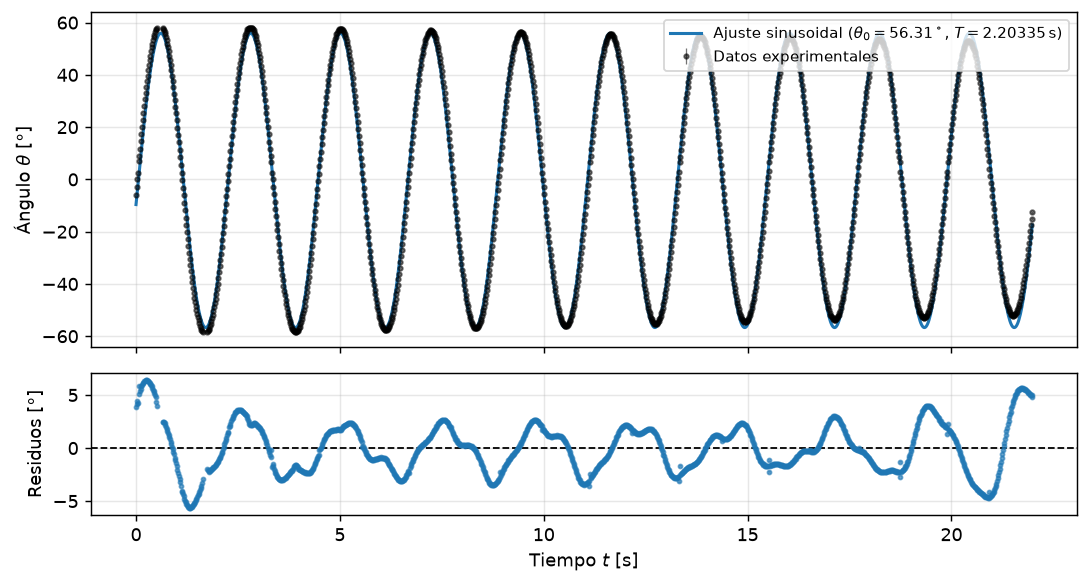

In [4]:
_ = analizar_y_graficar_video("IMG_1555")

### 1.2. Toma `IMG_1556`

IMG_1556: θ_0 = (44.14 ± 0.05)° | T = (2.15124 ± 0.00016) s | RMS res = 1.041° | χ²_red = 577.63 (ν = 1016)


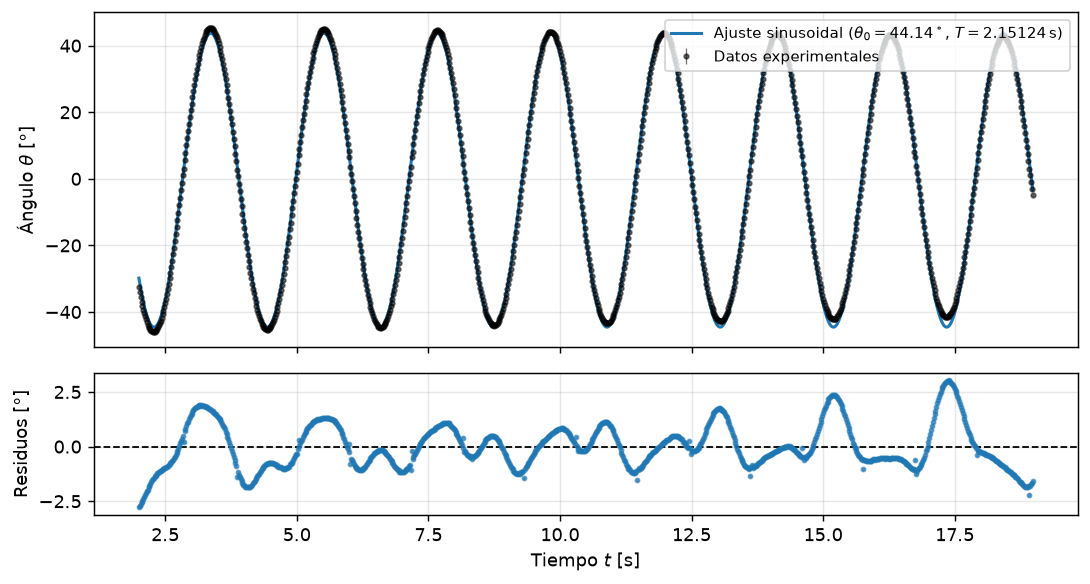

In [5]:
_ = analizar_y_graficar_video("IMG_1556")

### 1.3. Toma `IMG_1557`

IMG_1557: θ_0 = (36.54 ± 0.03)° | T = (2.12671 ± 0.00011) s | RMS res = 0.703° | χ²_red = 265.74 (ν = 1114)


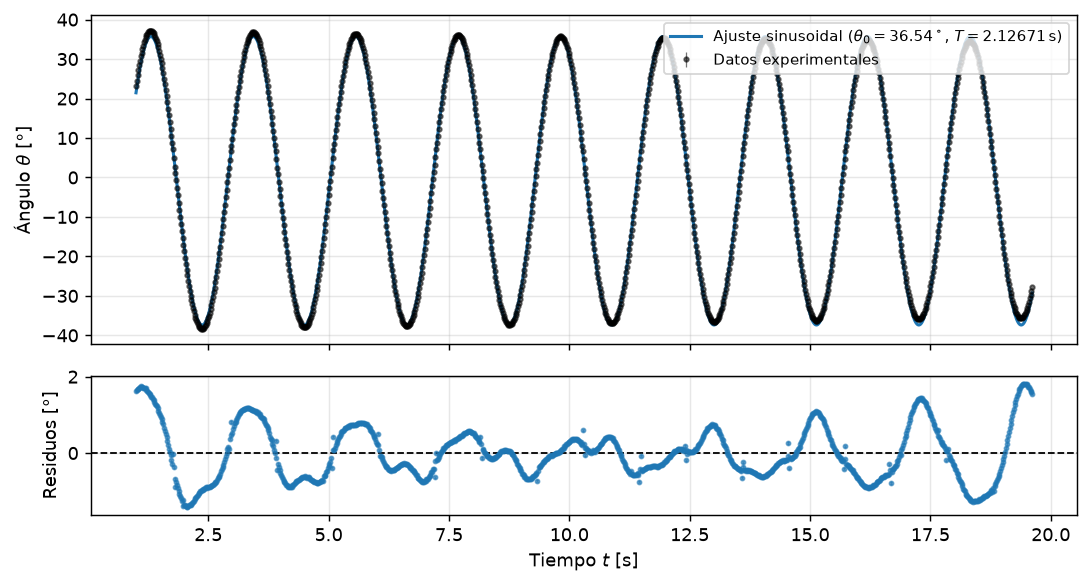

In [6]:
_ = analizar_y_graficar_video("IMG_1557")

### 1.4. Toma `IMG_1558`

IMG_1558: θ_0 = (23.93 ± 0.01)° | T = (2.09659 ± 0.00007) s | RMS res = 0.337° | χ²_red = 61.26 (ν = 1151)


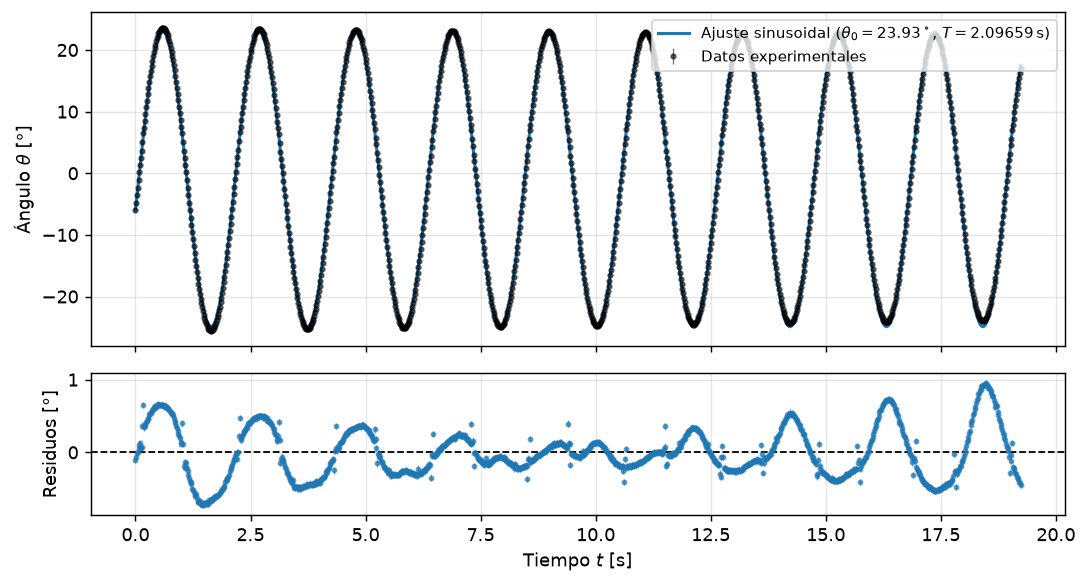

In [7]:
_ = analizar_y_graficar_video("IMG_1558")

### 1.5. Toma `IMG_1559`

IMG_1559: θ_0 = (18.36 ± 0.01)° | T = (2.08724 ± 0.00007) s | RMS res = 0.213° | χ²_red = 24.34 (ν = 1008)


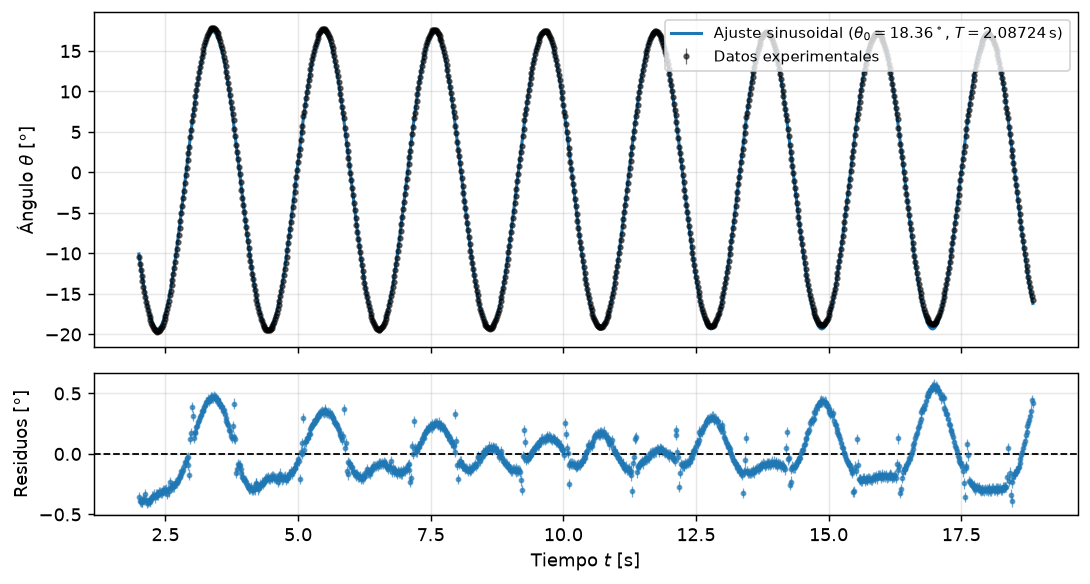

In [8]:
_ = analizar_y_graficar_video("IMG_1559")

### 1.6. Toma `IMG_1560`

IMG_1560: θ_0 = (15.97 ± 0.01)° | T = (2.08384 ± 0.00006) s | RMS res = 0.185° | χ²_red = 18.36 (ν = 1213)


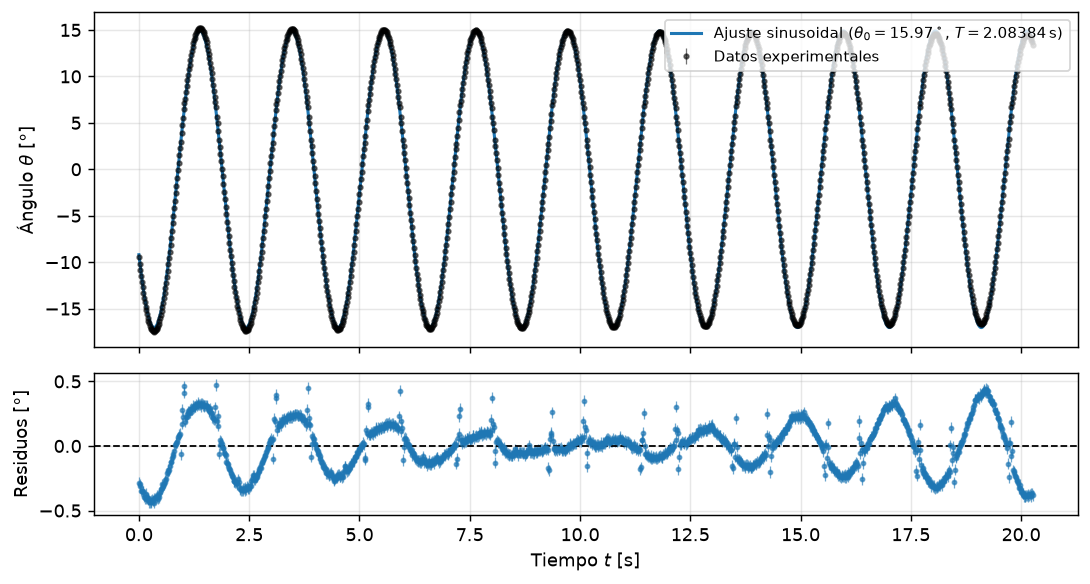

In [9]:
_ = analizar_y_graficar_video("IMG_1560")

### 1.7. Toma `IMG_1561`

IMG_1561: θ_0 = (12.77 ± 0.01)° | T = (2.08018 ± 0.00006) s | RMS res = 0.121° | χ²_red = 7.92 (ν = 1035)


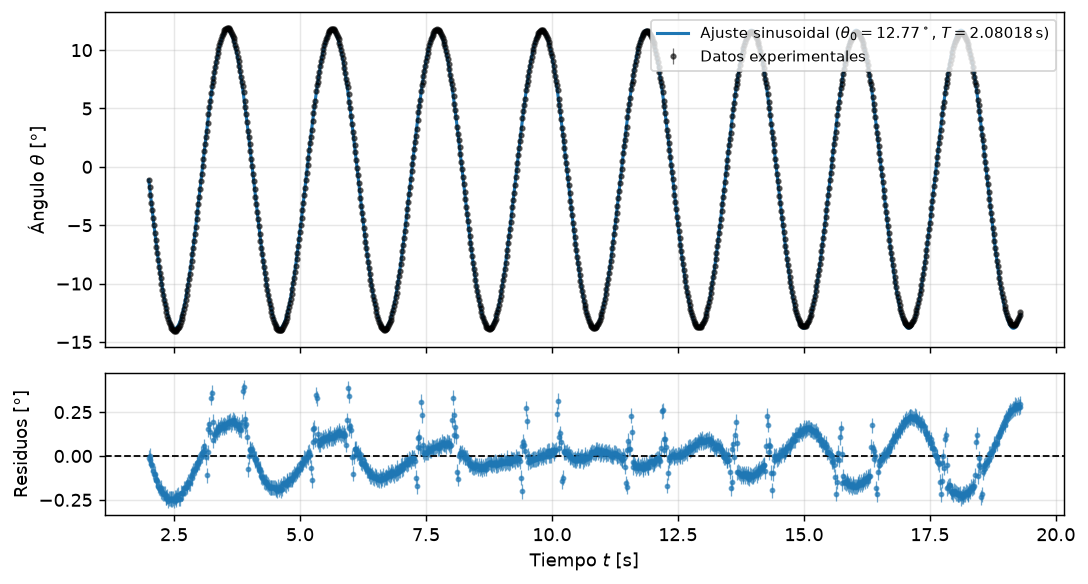

In [10]:
_ = analizar_y_graficar_video("IMG_1561")

### 1.8. Toma `IMG_1562`

IMG_1562: θ_0 = (10.45 ± 0.00)° | T = (2.07797 ± 0.00007) s | RMS res = 0.092° | χ²_red = 4.54 (ν = 896)


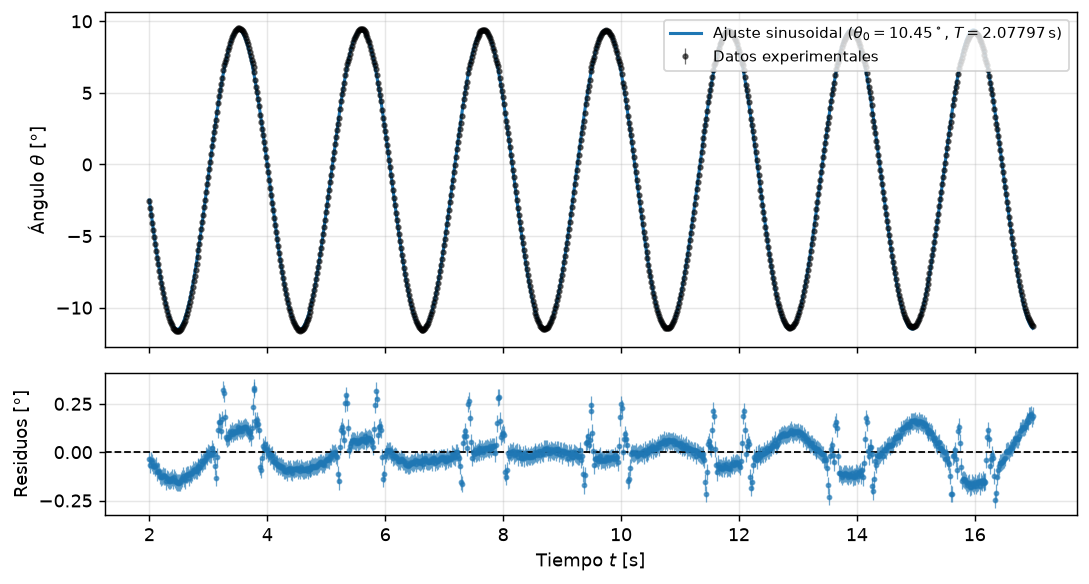

In [11]:
_ = analizar_y_graficar_video("IMG_1562")

### 1.9. Toma `IMG_1563`

IMG_1563: θ_0 = (11.22 ± 0.00)° | T = (2.07854 ± 0.00005) s | RMS res = 0.126° | χ²_red = 8.52 (ν = 1266)


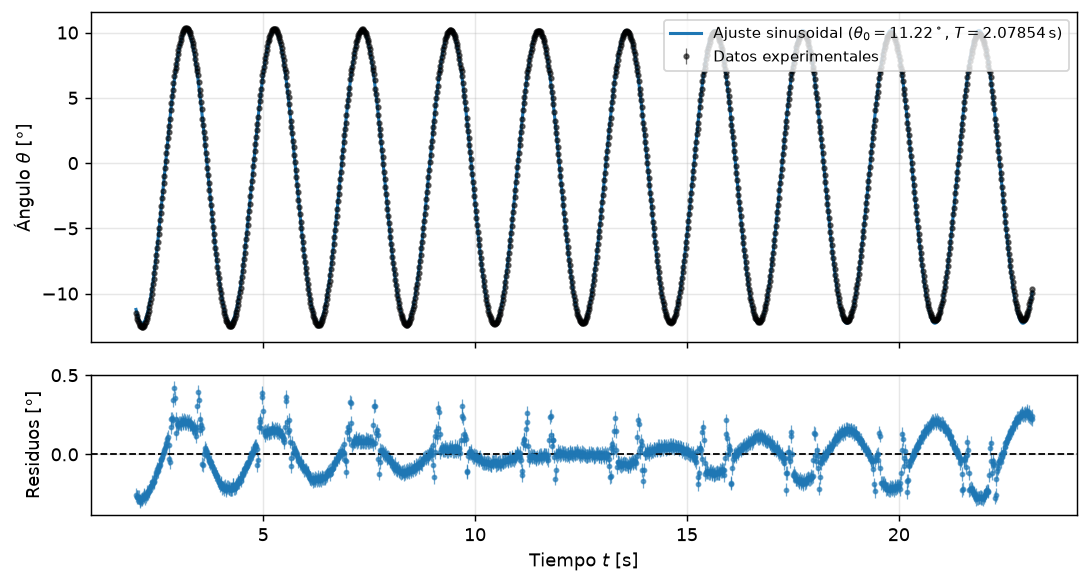

In [12]:
_ = analizar_y_graficar_video("IMG_1563")

### 1.10. Toma `IMG_1564`

IMG_1564: θ_0 = (8.90 ± 0.00)° | T = (2.07650 ± 0.00010) s | RMS res = 0.076° | χ²_red = 3.10 (ν = 682)


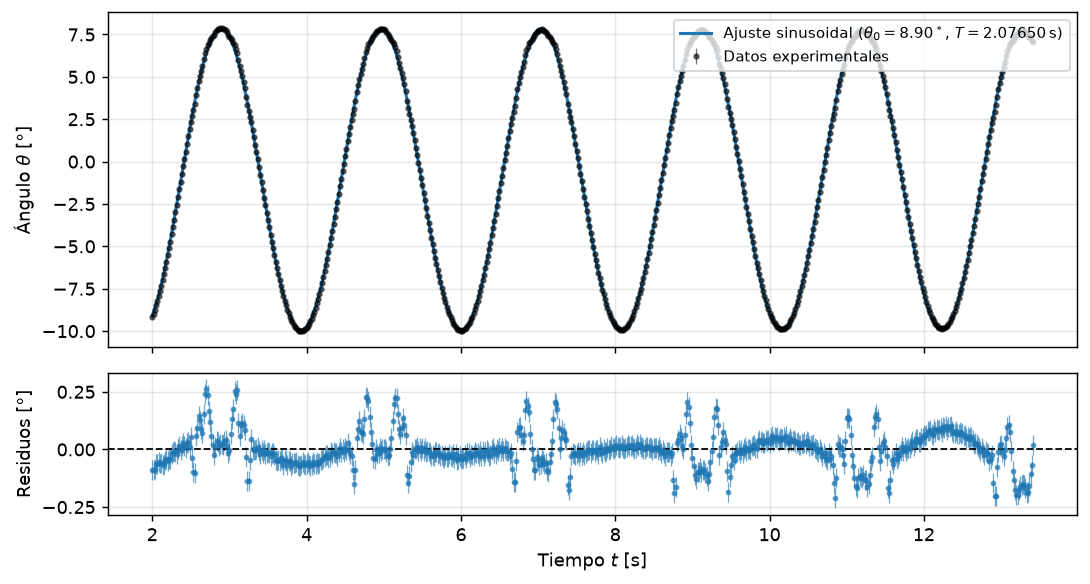

In [13]:
_ = analizar_y_graficar_video("IMG_1564")

### 1.11. Toma `IMG_1565`

IMG_1565: θ_0 = (8.03 ± 0.00)° | T = (2.07578 ± 0.00007) s | RMS res = 0.084° | χ²_red = 3.75 (ν = 950)


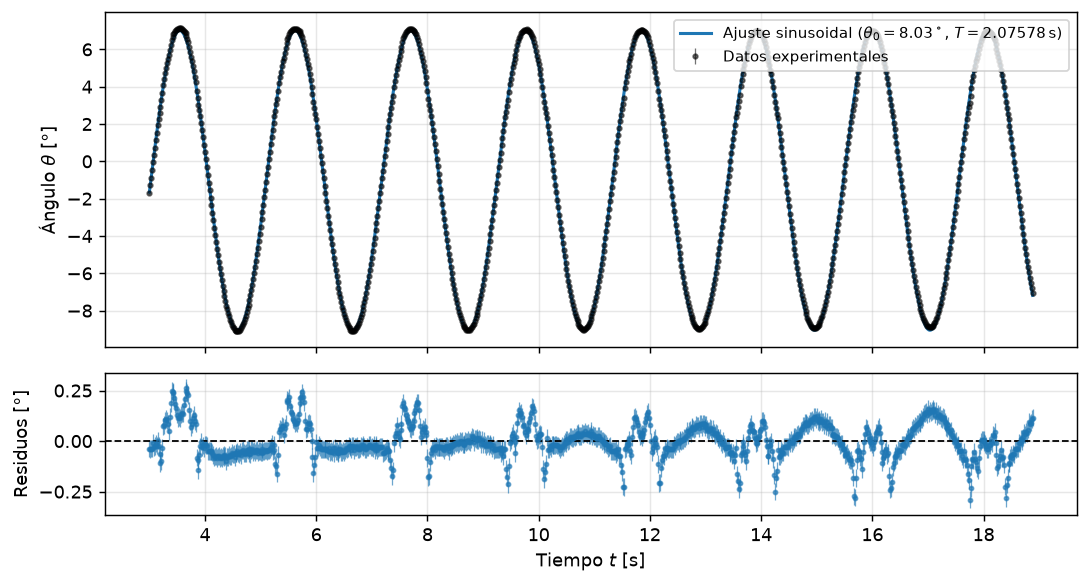

In [14]:
_ = analizar_y_graficar_video("IMG_1565")

### 1.12. Toma `IMG_1566`

IMG_1566: θ_0 = (6.50 ± 0.00)° | T = (2.07473 ± 0.00005) s | RMS res = 0.069° | χ²_red = 2.56 (ν = 1171)


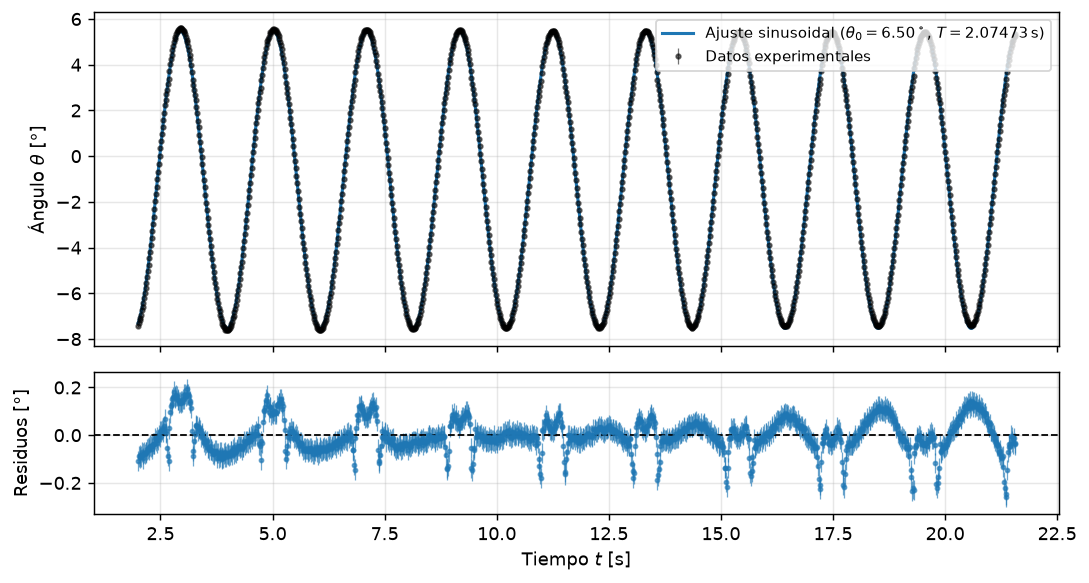

In [15]:
_ = analizar_y_graficar_video("IMG_1566")

### 1.13. Toma `IMG_1567`

IMG_1567: θ_0 = (3.78 ± 0.00)° | T = (2.07318 ± 0.00003) s | RMS res = 0.048° | χ²_red = 1.24 (ν = 2116)


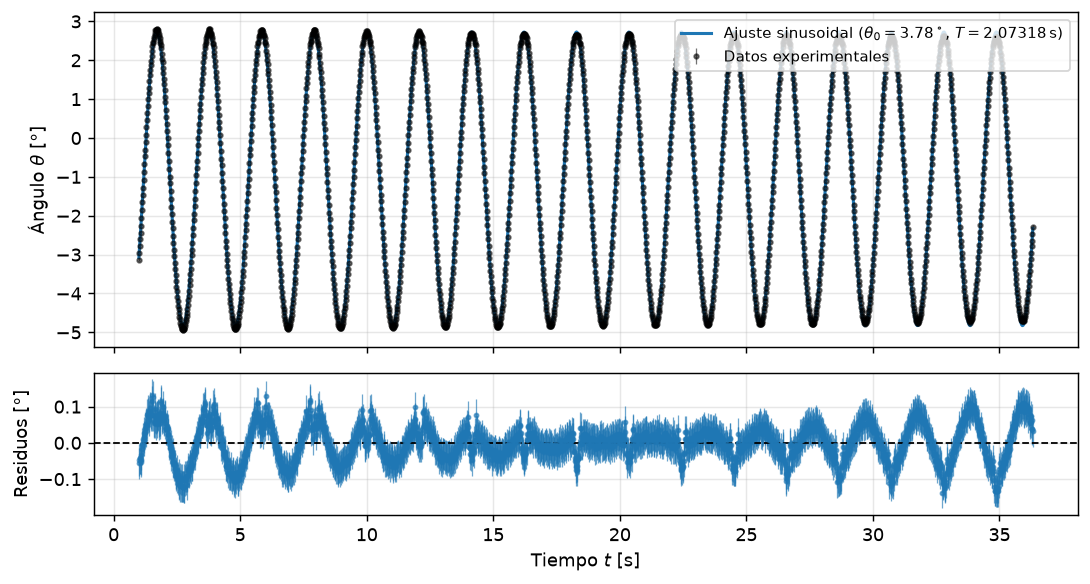

In [16]:
_ = analizar_y_graficar_video("IMG_1567")

### 1.14. Toma `IMG_1568`

IMG_1568: θ_0 = (2.16 ± 0.00)° | T = (2.07254 ± 0.00006) s | RMS res = 0.014° | χ²_red = 0.10 (ν = 807)


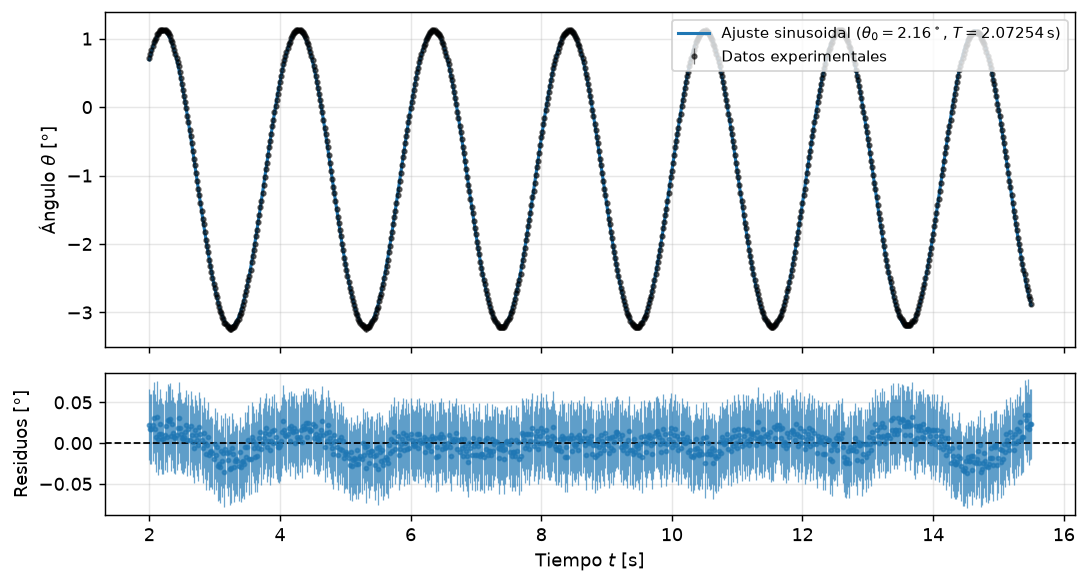

In [17]:
_ = analizar_y_graficar_video("IMG_1568")

### 1.15. Toma `IMG_1569` (excluida temporalmente para revisión manual)

Esta toma se ignora mientras `"IMG_1569"` esté en `EXCLUDED_VIDEOS`. Una vez verificado el recorte en `notebooks/debug_frame_detection.ipynb` y regenerado `results/trajectories.csv`, basta con quitar `"IMG_1569"` de `EXCLUDED_VIDEOS` en la sección 0.

In [18]:
if "IMG_1569" in EXCLUDED_VIDEOS:
    print("IMG_1569 excluido temporalmente (pendiente de verificación manual en debug_frame_detection.ipynb).")
else:
    _ = analizar_y_graficar_video("IMG_1569")

IMG_1569 excluido temporalmente (pendiente de verificación manual en debug_frame_detection.ipynb).


## 2. Comparación general y validez de la aproximación de ángulos pequeños

In [19]:
# --- Tabla resumen ordenada por amplitud angular θ_0 ---
filas_resumen = []
for vname, info in sorted(RESULTADOS.items(), key=lambda item: item[1]["theta0_deg"]):
    filas_resumen.append(
        {
            "Video": vname,
            "Fotogramas": info["n_frames"],
            "Duración [s]": info["duracion_s"],
            "θ_0 [°]": info["theta0_deg"],
            "σ_θ0 [°]": info["sigma_theta0_deg"],
            "T [s]": info["T_s"],
            "σ_T [s]": info["sigma_T_s"],
            "RMS residuos [°]": info["rms_res_deg"],
            "χ²_red": info["chi2_red"],
        }
    )

df_resumen = pd.DataFrame(filas_resumen)

# --- Período de referencia de pequeñas oscilaciones (T_0) ---
# 1) Toma de menor amplitud angular medida (IMG_1568, θ_0 ≈ 2,16°) y límite θ -> 0 mediante corrección de Borda
fila_ref = df_resumen.iloc[0]
VIDEO_REF = str(fila_ref["Video"])
T_REF_OBS = float(fila_ref["T [s]"])
SIGMA_T0_REF = float(fila_ref["σ_T [s]"])

theta_ref_rad = float(np.radians(fila_ref["θ_0 [°]"]))
T0_BORDA_LIM = T_REF_OBS / (1.0 + (theta_ref_rad ** 2) / 16.0)

# 2) Período teórico a partir de L = (75,8 ± 0,5) cm para registro informativo
T0_TEO_L = 2.0 * np.pi * np.sqrt(LARGO_CM / G_REF)
SIGMA_T0_TEO_L = 0.5 * T0_TEO_L * (SIGMA_L / LARGO_CM)

# --- Comparación ΔT = T - T_0 frente a la incerteza combinada σ_ΔT (criterio de 3σ) ---
# Usamos T0_BORDA_LIM como T_0 para que las 14 tomas tengan ΔT > 0 y puedan mostrarse en escala logarítmica
df_resumen["ΔT = T - T_0 [ms]"] = (df_resumen["T [s]"] - T0_BORDA_LIM) * 1e3
df_resumen["σ_ΔT [ms]"] = np.sqrt(df_resumen["σ_T [s]"] ** 2 + SIGMA_T0_REF ** 2) * 1e3
df_resumen["3σ_ΔT [ms]"] = 3.0 * df_resumen["σ_ΔT [ms]"]
df_resumen["|ΔT| / σ_ΔT"] = np.abs(df_resumen["ΔT = T - T_0 [ms]"]) / df_resumen["σ_ΔT [ms]"]
df_resumen["Compatible (3σ)"] = np.where(
    df_resumen["|ΔT| / σ_ΔT"] <= 3.0, "Sí", "No"
)

print(
    f"Referencia experimental de pequeñas oscilaciones ({VIDEO_REF}, θ_0 = {fila_ref['θ_0 [°]']:.2f}°): "
    f"T_obs = ({T_REF_OBS:.5f} ± {SIGMA_T0_REF:.5f}) s -> límite θ->0: T_0 = ({T0_BORDA_LIM:.5f} ± {SIGMA_T0_REF:.5f}) s"
)
print(
    f"Nota sobre constante L definida arriba (L_CM = {LARGO_CM*100:.2f} ± {SIGMA_L*100:.1f} cm): "
    f"2π√(L_CM/g) = ({T0_TEO_L:.4f} ± {SIGMA_T0_TEO_L:.4f}) s"
)
display(df_resumen.round(5))

Referencia experimental de pequeñas oscilaciones (IMG_1568, θ_0 = 2.16°): T_obs = (2.07254 ± 0.00006) s -> límite θ->0: T_0 = (2.07235 ± 0.00006) s
Nota sobre constante L definida arriba (L_CM = 75.75 ± 0.5 cm): 2π√(L_CM/g) = (1.7471 ± 0.0058) s


,Video,Fotogramas,Duración [s],θ_0 [°],σ_θ0 [°],T [s],σ_T [s],RMS residuos [°],χ²_red,ΔT = T - T_0 [ms],σ_ΔT [ms],3σ_ΔT [ms],|ΔT| / σ_ΔT,Compatible (3σ)
0,IMG_1568,811,13.5000,2.16307,0.00068,2.07254,0.00006,0.01360,0.09891,0.18460,0.07781,0.23344,2.37235,Sí
1,IMG_1567,2120,35.3167,3.77830,0.00148,2.07318,0.00003,0.04823,1.24087,0.82803,0.06097,0.18291,13.58102,No
2,IMG_1566,1175,19.5667,6.49764,0.00286,2.07473,0.00005,0.06892,2.55762,2.37714,0.07629,0.22887,31.15954,No
3,IMG_1565,954,15.8833,8.03131,0.00386,2.07578,0.00007,0.08354,3.75457,3.42489,0.08917,0.26751,38.40800,No
4,IMG_1564,686,11.4167,8.89581,0.00412,2.07650,0.00010,0.07599,3.10334,4.14992,0.11112,0.33336,37.34669,No
5,IMG_1562,900,14.9833,10.45170,0.00435,2.07797,0.00007,0.09190,4.54432,5.62197,0.08604,0.25811,65.34420,No
6,IMG_1563,1270,21.1500,11.21916,0.00498,2.07854,0.00005,0.12604,8.52271,6.18624,0.07534,0.22602,82.10987,No
7,IMG_1561,1039,17.3000,12.77207,0.00533,2.08018,0.00006,0.12140,7.92476,7.83381,0.08013,0.24038,97.76909,No
8,IMG_1560,1217,20.2667,15.97202,0.00747,2.08384,0.00006,0.18484,18.36355,11.49297,0.07894,0.23683,145.58571,No
9,IMG_1559,1012,16.8500,18.35924,0.00949,2.08724,0.00007,0.21287,24.34167,14.89314,0.09189,0.27568,162.06804,No


## 3. Figuras para Overleaf (sin títulos internos en Matplotlib)

Todas las figuras destinadas al informe se generan y exportan **sin `ax.set_title` ni `fig.suptitle`**, colocando los títulos breves en `\subcaption{...}` y la explicación detallada `(a) ..., (b) ...` en `\caption{...}`.

Figura exportada: ../docs/figures/fig_theta_pequena.png
Figura exportada: ../docs/figures/fig_theta_grande.png
Figura exportada: ../docs/figures/fig_periodo_vs_amplitud.png


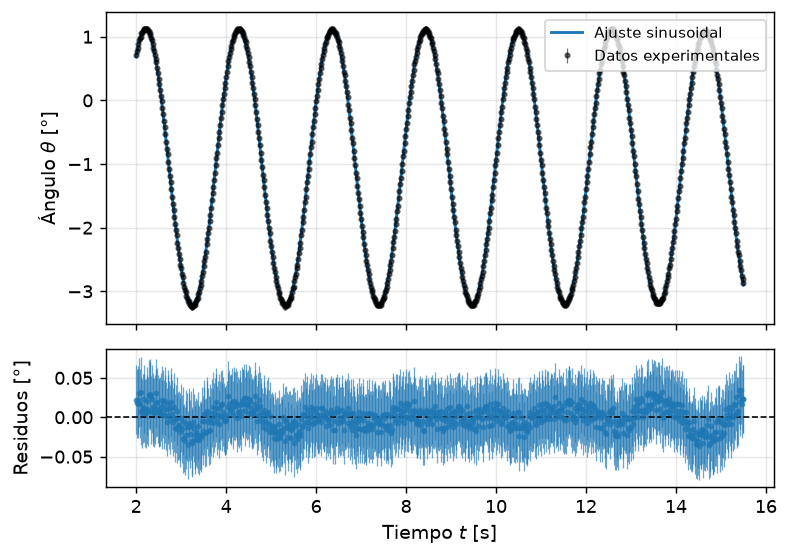

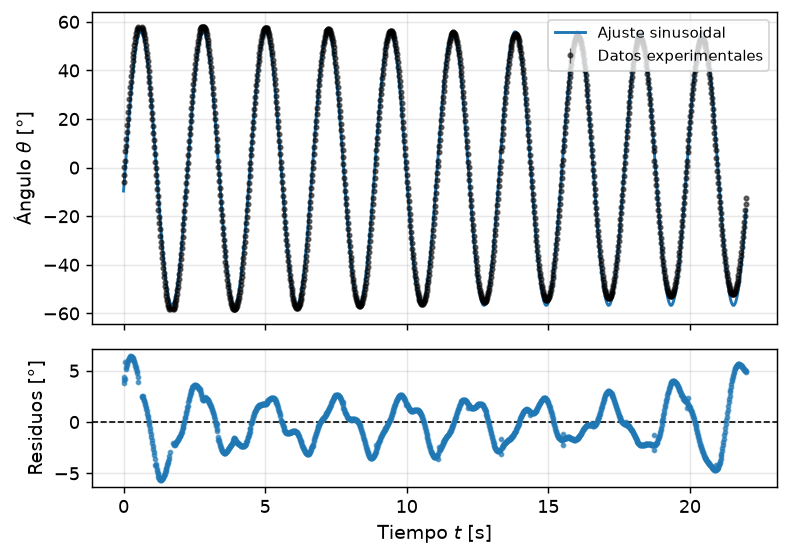

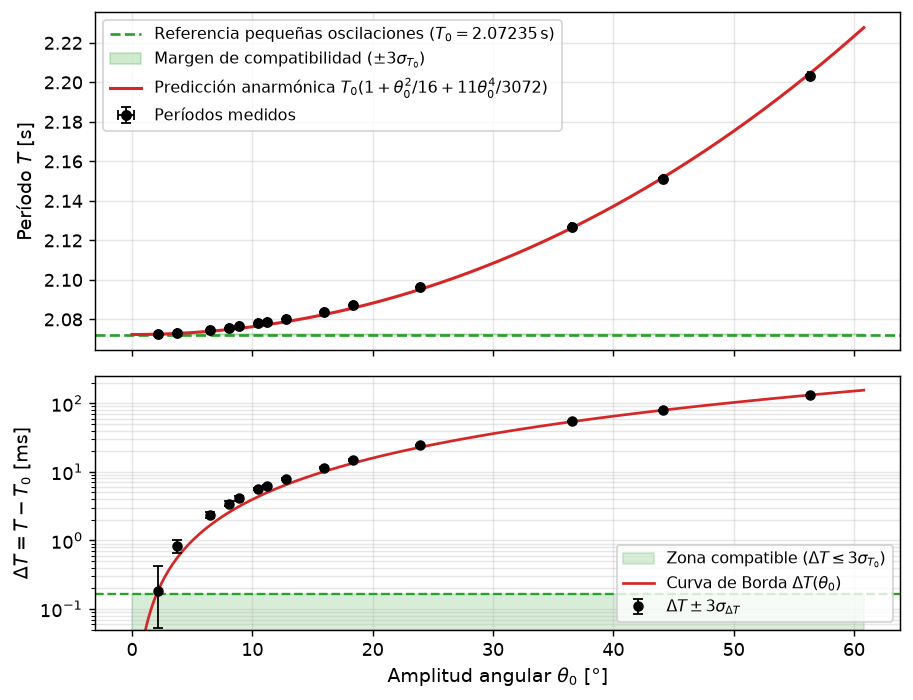

In [20]:
# Directorio de salida para subir las figuras a Overleaf
FIG_DIR = Path("../docs/figures") if Path("../docs").exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def exportar_figura_toma(video_name: str, out_path: Path) -> None:
    """Exporta la serie angular θ(t), su ajuste sinusoidal y los residuos sin título interno."""
    info = RESULTADOS[video_name]
    t = info["t"]
    tau = info["tau"]
    tau_fine = np.linspace(0.0, float(tau[-1]), 1400)
    t_fine = float(t[0]) + tau_fine
    fit_fine_deg = np.degrees(modelo_sinusoidal(tau_fine, *info["popt"]))

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(6.2, 4.4), sharex=True, gridspec_kw={"height_ratios": [2.5, 1.1]}
    )
    ax_top.errorbar(
        t,
        info["theta_deg"],
        yerr=info["sigma_theta_deg"],
        fmt="o",
        markersize=2.4,
        color="black",
        alpha=0.55,
        elinewidth=0.7,
        label="Datos experimentales",
    )
    ax_top.plot(
        t_fine,
        fit_fine_deg,
        color="C0",
        lw=1.6,
        label="Ajuste sinusoidal",
    )
    ax_top.set_ylabel(r"Ángulo $\theta$ [°]", fontsize=10.5)
    ax_top.legend(loc="upper right", fontsize=8.5, frameon=True)
    ax_top.grid(True, alpha=0.3)

    ax_bot.errorbar(
        t,
        info["residuos_deg"],
        yerr=info["sigma_theta_deg"],
        fmt="o",
        markersize=2.2,
        color="C0",
        alpha=0.65,
        elinewidth=0.7,
    )
    ax_bot.axhline(0.0, color="black", linestyle="--", lw=0.9)
    ax_bot.set_ylabel("Residuos [°]", fontsize=10.5)
    ax_bot.set_xlabel("Tiempo $t$ [s]", fontsize=10.5)
    ax_bot.grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Figura exportada: {out_path}")


# --- Figura para §3.1: Dos tomas representativas (pequeña y gran amplitud) ---
exportar_figura_toma("IMG_1568", FIG_DIR / "fig_theta_pequena.png")
exportar_figura_toma("IMG_1555", FIG_DIR / "fig_theta_grande.png")

# --- Figura para §3.2: Período T (lineal) y diferencia ΔT = T - T_0 (escala logarítmica en y) ---
theta_grid_deg = np.linspace(0.0, float(df_resumen["θ_0 [°]"].max()) * 1.08, 400)
theta_grid_rad = np.radians(theta_grid_deg)
T_borda_grid = T0_BORDA_LIM * (
    1.0 + (theta_grid_rad ** 2) / 16.0 + (11.0 * (theta_grid_rad ** 4)) / 3072.0
)

fig, (ax_T, ax_dT) = plt.subplots(
    2, 1, figsize=(7.2, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.5]}
)

# Panel superior (escala lineal): T(θ_0) medido, referencia T_0 y expansión de Borda
ax_T.axhline(
    T0_BORDA_LIM,
    color="C2",
    linestyle="--",
    lw=1.5,
    label=rf"Referencia pequeñas oscilaciones ($T_0 = {T0_BORDA_LIM:.5f}\,\mathrm{{s}}$)",
)
ax_T.fill_between(
    theta_grid_deg,
    T0_BORDA_LIM - 3.0 * SIGMA_T0_REF,
    T0_BORDA_LIM + 3.0 * SIGMA_T0_REF,
    color="C2",
    alpha=0.22,
    label=r"Margen de compatibilidad ($\pm 3\sigma_{T_0}$)",
)
ax_T.plot(
    theta_grid_deg,
    T_borda_grid,
    color="C3",
    lw=1.7,
    label=r"Predicción anarmónica $T_0(1 + \theta_0^2/16 + 11\theta_0^4/3072)$",
)
ax_T.errorbar(
    df_resumen["θ_0 [°]"],
    df_resumen["T [s]"],
    xerr=df_resumen["σ_θ0 [°]"],
    yerr=df_resumen["σ_T [s]"],
    fmt="o",
    markersize=5.0,
    color="black",
    capsize=2.5,
    elinewidth=1.0,
    zorder=5,
    label="Períodos medidos",
)
ax_T.set_ylabel("Período $T$ [s]", fontsize=10.5)
ax_T.legend(loc="upper left", fontsize=8.8, frameon=True)
ax_T.grid(True, alpha=0.3)

# Panel inferior (escala logarítmica en y): ΔT = T - T_0 [ms]
y_floor = 0.05
thresh_3sigma_ms = 3.0 * SIGMA_T0_REF * 1e3
ax_dT.set_yscale("log")
ax_dT.set_ylim(bottom=y_floor, top=250.0)

ax_dT.axhline(
    thresh_3sigma_ms,
    color="C2",
    linestyle="--",
    lw=1.3,
)
ax_dT.fill_between(
    theta_grid_deg,
    y_floor,
    thresh_3sigma_ms,
    color="C2",
    alpha=0.18,
    label=r"Zona compatible ($\Delta T \leq 3\sigma_{T_0}$)",
)

mask_pos = theta_grid_deg > 0.0
ax_dT.plot(
    theta_grid_deg[mask_pos],
    (T_borda_grid[mask_pos] - T0_BORDA_LIM) * 1e3,
    color="C3",
    lw=1.5,
    label=r"Curva de Borda $\Delta T(\theta_0)$",
)

y_vals = df_resumen["ΔT = T - T_0 [ms]"].to_numpy()
y_err = df_resumen["3σ_ΔT [ms]"].to_numpy()
y_err_low = np.minimum(y_err, np.maximum(0.0, y_vals - y_floor * 1.05))
ax_dT.errorbar(
    df_resumen["θ_0 [°]"],
    y_vals,
    yerr=[y_err_low, y_err],
    fmt="o",
    markersize=4.8,
    color="black",
    capsize=2.5,
    elinewidth=1.0,
    zorder=5,
    label=r"$\Delta T \pm 3\sigma_{\Delta T}$",
)
ax_dT.set_ylabel(r"$\Delta T = T - T_0$ [ms]", fontsize=10.5)
ax_dT.set_xlabel(r"Amplitud angular $\theta_0$ [°]", fontsize=10.5)
ax_dT.legend(loc="lower right", fontsize=8.6, frameon=True)
ax_dT.grid(True, which="both", alpha=0.3)

fig.tight_layout()
out_periodo = FIG_DIR / "fig_periodo_vs_amplitud.png"
fig.savefig(out_periodo, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figura exportada: {out_periodo}")